# Loading data & libraries

In [65]:
import pandas as pd
import numpy as np

data = pd.read_csv('aciertos_unam_2021_2026.csv')
print(data.shape)
data.head()

(1027716, 7)


,folio,aciertos,acreditado,año,area,carrera,plantel
0,1,71.0,NaN,2021,1,ACTUARIA,FACULTAD DE CIENCIAS
1,30,93.0,NaN,2021,1,ACTUARIA,FACULTAD DE CIENCIAS
2,56,49.0,NaN,2021,1,ACTUARIA,FACULTAD DE CIENCIAS
3,133,90.0,NaN,2021,1,ACTUARIA,FACULTAD DE CIENCIAS
4,148,62.0,NaN,2021,1,ACTUARIA,FACULTAD DE CIENCIAS


In [66]:
print(data.isnull().sum())
print(data['acreditado'].unique())
print(data['acreditado'].value_counts())

folio              0
aciertos      153694
acreditado    789555
año                0
area               0
carrera            0
plantel            0
dtype: int64
[nan 'S' 'N' 'C']
acreditado
N    147645
S     87422
C      3094
Name: count, dtype: int64


In [67]:
#Eliminating rows with nulls & values = 0 in the "aciertos" variable because it means either the aspirant did not attempt the exam, they had to leave early, etc.
data = data[data['aciertos'].notna() & (data['aciertos'] > 0)].copy()

In [68]:
print(data.shape)
print(data.isnull().sum())
print(data['acreditado'].unique())
print(data['acreditado'].value_counts())

(873895, 7)
folio              0
aciertos           0
acreditado    786474
año                0
area               0
carrera            0
plantel            0
dtype: int64
[nan 'S']
acreditado
S    87421
Name: count, dtype: int64


### Data splitting by year

In [69]:
#Data grupby year for future iterations.
sets = {año: data[data['año'] == año] for año in range(2021, 2027)}

#Sets creation for comparing 2026 vs past years.
hist = data[data['año'].between(2021, 2025)]
set_2026 = data[data['año'] == 2026]

In [70]:
#Statistics from previous years
datos_historicos = data.groupby('año')['aciertos'].agg(['mean','median','std','min','max']).round(2)
print(datos_historicos)

       mean  median    std  min    max
año                                   
2021  56.09    52.0  18.71  4.0  120.0
2022  54.90    51.0  18.55  1.0  119.0
2023  56.10    52.0  18.92  7.0  120.0
2024  56.05    52.0  19.69  1.0  120.0
2025  56.37    52.0  19.74  6.0  120.0
2026  71.18    71.0  25.17  1.0  120.0


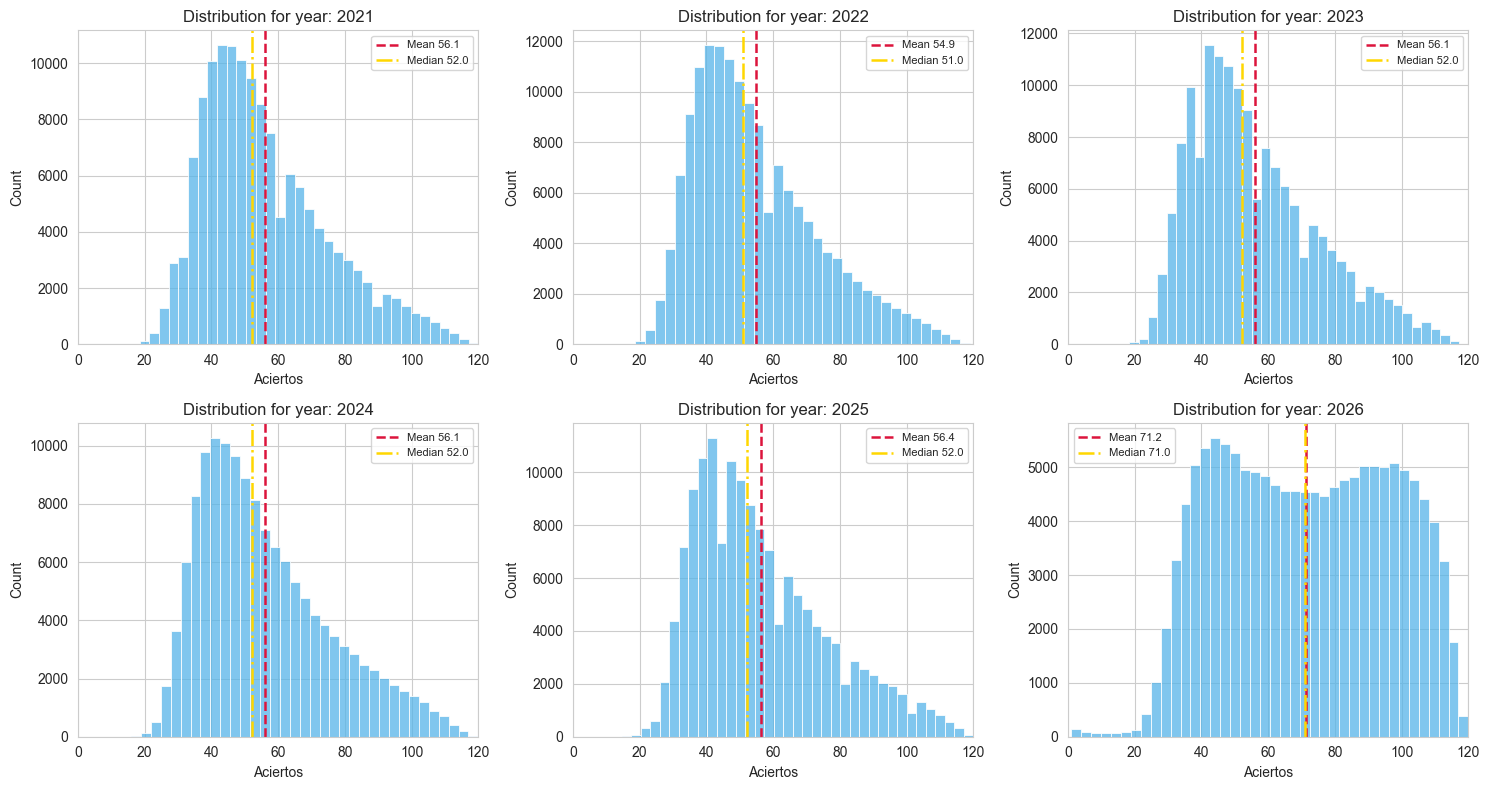

In [71]:
#First look at the histograms per year 

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, año in enumerate(range(2021, 2027)):
    d = sets[año]['aciertos']
    sns.histplot(x=d, bins=40, ax=axes[i], color = '#56B4E9')
    mean = d.mean()
    median = d.median()
    axes[i].axvline(mean,   color='crimson',    ls='--', lw=1.8,
                    label=f'Mean {mean:.1f}')
    axes[i].axvline(median, color='gold', ls='-.', lw=1.8,
                    label=f'Median {median:.1f}')
    axes[i].set_title(f'Distribution for year: {año}')
    axes[i].set_xlabel('Aciertos')
    axes[i].set_xlim(0, 120)
    axes[i].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [72]:
#Skewness & kurtosis for measuring the change in the distribution.
from scipy.stats import skew, kurtosis

stats_form = pd.DataFrame({
    'skewness': [skew(sets[a]['aciertos']) for a in range(2021, 2027)],
    'kurtosis': [kurtosis(sets[a]['aciertos']) for a in range(2021, 2027)],
    'mean': [sets[a]['aciertos'].mean() for a in range(2021, 2027)],
    'median': [sets[a]['aciertos'].median() for a in range(2021, 2027)],
}, index=range(2021, 2027))
stats_form.index.name = 'año'

print(stats_form.round(3))

      skewness  kurtosis    mean  median
año                                     
2021     0.813     0.158  56.088    52.0
2022     0.838     0.218  54.899    51.0
2023     0.764    -0.009  56.097    52.0
2024     0.779    -0.048  56.053    52.0
2025     0.806     0.017  56.370    52.0
2026    -0.014    -1.107  71.182    71.0


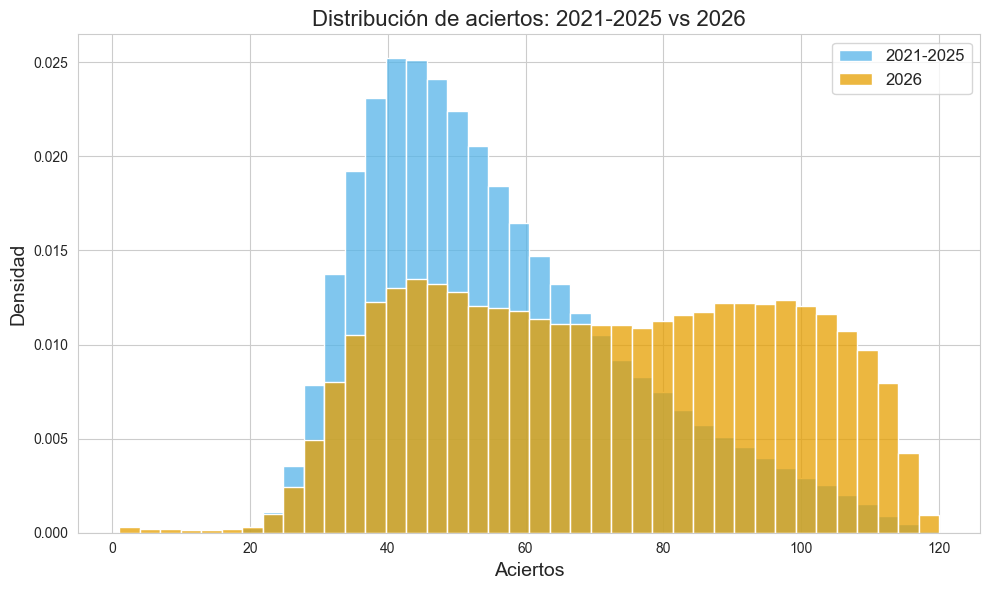

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize = (10, 6))
sns.histplot(x=hist['aciertos'], bins=40, color = '#56B4E9', label='2021-2025', stat='density')
sns.histplot(x=set_2026['aciertos'], bins=40, color = '#E69F00', label='2026', stat='density')
plt.title('Distribución de aciertos: 2021-2025 vs 2026', fontsize=16)
plt.xlabel('Aciertos', fontsize=14)
plt.ylabel('Densidad', fontsize=14)
plt.legend(fontsize=12)

plt.tight_layout()
plt.savefig('Dist_2021-2025_vs_2026.png', dpi=150, bbox_inches='tight')
plt.show()

## KL-Divergence applied to the distributions (P: 2026   |   Q: 2021-2025)

In [80]:
from scipy.stats import entropy

bins = np.arange(0, 122, 1)
kl = []

def a_distribution(aciertos, bins):
    "Normalized histogram to probability,anti-log(0) smoothing."
    h, _ = np.histogram(aciertos, bins=bins)
    p = h.astype(float) + 1e-9   
    return p / p.sum()                

P = a_distribution(set_2026['aciertos'], bins)
Q = a_distribution(hist['aciertos'], bins)

kl_main = entropy(P, Q)
kl.append(kl_main)
print(f"KL(2026 || 2021-2025) = {kl_main:.4f} nats\n")

kl_baseline = []
for y in range(2021, 2025):
    P = a_distribution(sets[y+1]['aciertos'], bins)
    Q = a_distribution(sets[y]['aciertos'], bins)
    kl_y = entropy(P, Q)
    kl_baseline.append(kl)
    kl.append(kl_y)
    print(f"KL({y+1} || {y}) = {kl_y:.4f} nats")

KL(2026 || 2021-2025) = 0.3387 nats

KL(2022 || 2021) = 0.0041 nats
KL(2023 || 2022) = 0.0032 nats
KL(2024 || 2023) = 0.0039 nats
KL(2025 || 2024) = 0.0021 nats


In [75]:
#KS-test applied over the whole historical data vs 2026
#The test was also applied between each year for comparison
#Using D statistic as the main value to look for since p_value is highly sensible when working with such large data
from scipy.stats import ks_2samp

hist_scores = data[data['año'].between(2021, 2025)]['aciertos']
scores_2026 = data[data['año'] == 2026]['aciertos']

ks_main = ks_2samp(scores_2026, hist_scores)
print("=== KS-test: 2026 vs historical 2021-2025 ===")
print(f"D statistic = {ks_main.statistic:.4f}")
print(f"p-value     = {ks_main.pvalue:.3e}")

print("\n=== Year-over-year KS (historical baseline of 'normal' D) ===")
ks_baseline = []
for y in range(2021, 2025):
    r = ks_2samp(sets[y+1]['aciertos'], sets[y]['aciertos'])
    ks_baseline.append(r.statistic)
    print(f"  {y+1} vs {y}: D = {r.statistic:.4f}  (p = {r.pvalue:.2e})")

import numpy as np
baseline_max = np.max(ks_baseline)
print(f"\n2026 D = {ks_main.statistic:.4f} is {ks_main.statistic/baseline_max:.0f}x "
      f"the largest historical year-over-year D ({baseline_max:.4f})")

=== KS-test: 2026 vs historical 2021-2025 ===
D statistic = 0.2932
p-value     = 0.000e+00

=== Year-over-year KS (historical baseline of 'normal' D) ===
  2022 vs 2021: D = 0.0314  (p = 3.49e-63)
  2023 vs 2022: D = 0.0275  (p = 8.50e-51)
  2024 vs 2023: D = 0.0171  (p = 5.80e-19)
  2025 vs 2024: D = 0.0095  (p = 4.59e-06)

2026 D = 0.2932 is 9x the largest historical year-over-year D (0.0314)


C:\Users\emmys\AppData\Local\Temp\ipykernel_37640\3556134589.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = range(2021, 2026), y = kl_r, palette = 'Blues_d')


<Axes: >

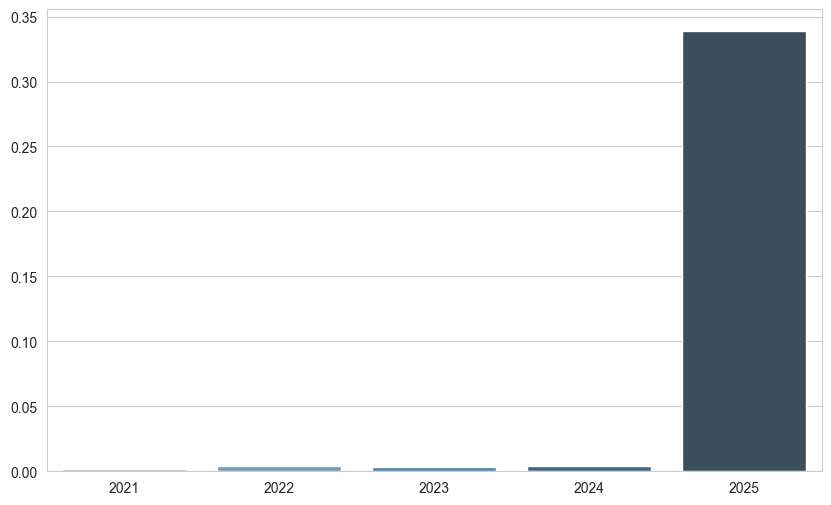

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns
kl_r = kl[::-1]
plt.figure(figsize = (10, 6))
sns.barplot(x = range(2021, 2026), y = kl_r, palette = 'Blues_d')

## Deep analysis per area to show the anomaly isnt uniform

In [77]:
from scipy.stats import entropy, ks_2samp

area_names = {
    1: 'Physical-Math & Engineering',
    2: 'Biological, Chemical & Health',
    3: 'Social Sciences',
    4: 'Humanities & Arts'
}
bins = np.arange(0, 122, 1)

def to_dist(scores, bins):
    h, _ = np.histogram(scores, bins=bins)
    p = h.astype(float) + 1e-9
    return p / p.sum()

rows = []
for a in [1, 2, 3, 4]:
    sub = data[data['area'] == a]
    base = sub[sub['año'].between(2021, 2025)]['aciertos']
    y26  = sub[sub['año'] == 2026]['aciertos']

    # KL(2026 || historical)
    kl = entropy(to_dist(y26, bins), to_dist(base, bins))
    # KS
    ks = ks_2samp(y26, base)
    rows.append({
        'area': area_names[a],
        'KL_nats': kl,
        'KS_D': ks.statistic,
        'median_base': base.median(),
        'median_2026': y26.median(),
        'pct100_base': (base >= 100).mean() * 100,
        'pct100_2026': (y26 >= 100).mean() * 100,
        'n_2026': len(y26)
    })

per_area = pd.DataFrame(rows).set_index('area').round(3)
print(per_area)

                               KL_nats   KS_D  median_base  median_2026  \
area                                                                      
Physical-Math & Engineering      0.289  0.267         53.0         71.0   
Biological, Chemical & Health    0.389  0.307         52.0         73.0   
Social Sciences                  0.444  0.324         52.0         72.0   
Humanities & Arts                0.207  0.207         51.0         63.0   

                               pct100_base  pct100_2026  n_2026  
area                                                             
Physical-Math & Engineering          3.830       15.062   30049  
Biological, Chemical & Health        3.475       20.618   62742  
Social Sciences                      2.155       15.385   34033  
Humanities & Arts                    2.217        7.165   11458  


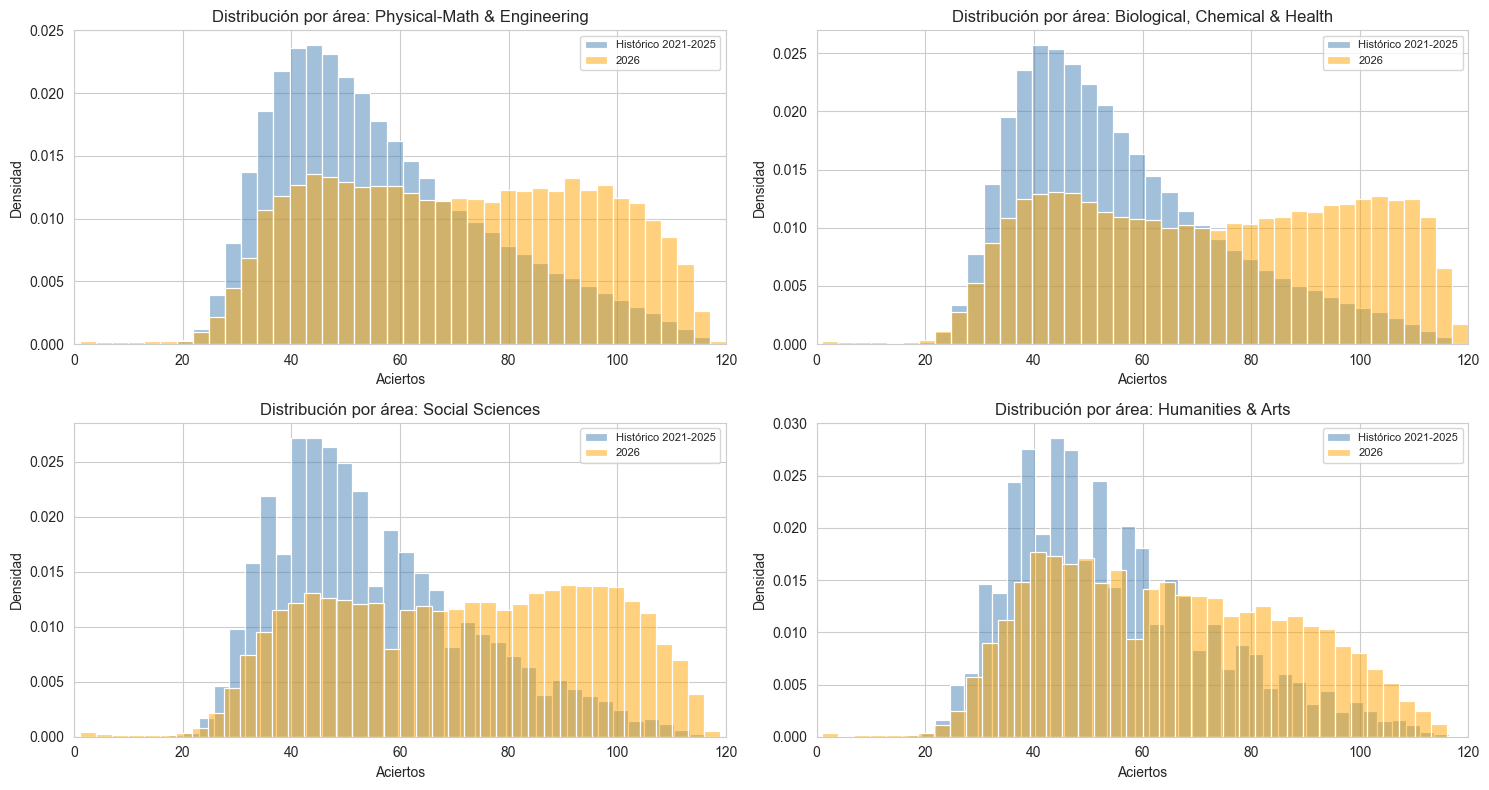

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()

for a in [1, 2, 3, 4]:
    dt = data[data['area'] == a]
    base = dt[dt['año'].between(2021, 2025)]['aciertos']
    y26 = dt[dt['año'] == 2026]['aciertos']
    sns.histplot(x=base, bins=40, ax=axes[a-1], color='steelblue',
             stat='density', alpha=0.5, label='Histórico 2021-2025')
    sns.histplot(x=y26, bins=40, ax=axes[a-1], color='orange',
             stat='density', alpha=0.5, label='2026')
    axes[a-1].set_title(f'Distribución por área: {area_names[a]}')
    axes[a-1].set_title(f'Distribución por área: {area_names[a]}')
    axes[a-1].set_xlabel('Aciertos')
    axes[a-1].set_ylabel('Densidad')
    axes[a-1].set_xlim(0, 120)
    axes[a-1].legend(fontsize=8)
    

plt.tight_layout()
plt.savefig('Distribución_por_area.png', dpi=150, bbox_inches='tight')
plt.show()